# Third year CH2306

In [1]:
import particlespy as ps # this whole section is loading the information and code needed from different python packages
import numpy as np
import matplotlib.pyplot as plt
import hyperspy.api as hs
import pandas as pd
import cv2

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
from segment_anything.utils import transforms
import torch
import sys
import h5py
import json

from skimage import exposure
from skimage.measure import regionprops,regionprops_table
from skimage.segmentation import clear_border
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

In [2]:
%matplotlib inline

## Segement anything - NP commands
by https://github.com/ArdaGen/STEM-Automated-Nanoparticle-Analysis-YOLOv8-SAM/tree/main/scripts

In [3]:
# -*- coding: utf-8 -*-
"""
Created on Fri Jul 28 16:11:43 2023

@author: ardag
"""

def particle_analysis(masks, boxes, pixel_size,path_to_csv_file, save=False):
    Diameter = []
    Area = []
    pixel_size = pixel_size  #* pixel_scale 
    for i in range(len(boxes)):
      mask = masks[i,:,:]
      mask = clear_border(mask)
      properties = ['area']
      props = regionprops_table(mask, properties=properties)
      y = props['area']
      A = y*pixel_size*pixel_size
      Area.append(A)
      D = (np.sqrt(A/3.14))*2
      Diameter.append(D)
      
    
    Diameter = [i for i in Diameter if i > 0]
    Diameter = np.array(Diameter)
    Area = [i for i in Area if i > 0]
    Area = np.array(Area)
    print('Mean Diameter : ' + str(np.round(np.mean(Diameter),2)) +' nm')
    print('Mean Area : ' + str(np.round(np.mean(Area),2))+' nm\u00b2') 
    
    fig, axs = plt.subplots(1, 2, sharey = False, tight_layout = False, figsize=(5, 3))
    axs[0].hist(Diameter, bins = 30, facecolor='#2ab0ff', edgecolor='#e0e0e0', linewidth=0.5, alpha=0.7)
    axs[0].set_title("Diameter")
    axs[0].set_xlabel('nm')
    axs[1].hist(Area, bins = 30, facecolor='red', edgecolor='#e0e0e0', linewidth=0.5, alpha=0.7)
    axs[1].set_title("Area")
    axs[1].set_xlabel('nm\u00b2')
    
    if save == True:
        Diameter= np.concatenate(Diameter)
        Area = np.concatenate(Area)
        dict = {'Diameter (nm)' : Diameter,'Area (nm2)' : Area}
        df = pd.DataFrame(dict)
        df.to_csv(path_to_csv_file)
    plt.show()
    return Diameter, Area

def object_detection (img_x, img, path_to_image, img_size=1024, pred_score = 0.25, overlap_thr =0.5, save = False, s_txt = False):
    from ultralytics import YOLO
    path_to_weights_obj = "best12x.pt" # Weights for the YOLO
    model = YOLO(path_to_weights_obj)
    model.to('cuda')
    # Run detection on the image
    results = model.predict(source = img_x, imgsz = img_size, conf = pred_score, max_det= 4000, iou = overlap_thr, save_txt = s_txt)
    
    # Get bounding boxes
    for result in results:
        boxes = result.boxes
     
    bbox = boxes.xyxy.tolist()
    #class_id=results[0].boxes.cls.cpu().numpy().astype(int)
    #points = [item[:2] for item in bbox]
    # Visualize bounding boxes
    res_plotted = results[0].plot(labels=False, line_width=2, img=img)
    plt.figure(figsize=(8, 8))
    plt.axis('off')
    plt.imshow(res_plotted)
    if save == True:
        plt.savefig(path_to_image,bbox_inches='tight', pad_inches = 0)
    plt.show()
    #plot_bboxes(img, results[0].boxes.boxes, score=False)
    
    return bbox


def segmentation(img, bbox, erode = False, dilate = False, kernel_size =(5, 5) ):


    # Load the model
    sam_checkpoint = r"E:\Coding\SegmentAnythingModel\ArdaGen_STEM\sam_vit_b_01ec64.pth" # weights for the SAM path
    model_type = "vit_b"
    device = "cuda"
    sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
    sam.to(device=device)
    predictor = SamPredictor(sam)


    # Run model on the image
    predictor.set_image(img)


    input_boxes = torch.tensor(bbox, device=predictor.device)
    transformed_boxes = predictor.transform.apply_boxes_torch(input_boxes, img.shape[:2])
    masks, _, _ = predictor.predict_torch(
        point_coords=None,
        point_labels=None,
        boxes=transformed_boxes,
        multimask_output=False,
    )
    
    masks_array = masks.cpu().numpy().squeeze()
    masks3D_array = masks_array.astype('uint8')
    
    if erode == True:
        # Erode
        
        kernel = np.ones((kernel_size), np.uint8)
        masks3D_erode = []
        for mask in masks3D_array:
            mask = cv2.erode(mask, kernel)
            masks3D_erode.append(mask)
        masks3D_erode = np.asarray(masks3D_erode)
        masks3D_array = masks3D_erode 
        
    if dilate == True:
        # Erode
        
        kernel = np.ones((kernel_size), np.uint8)
        masks3D_erode = []
        for mask in masks3D_array:
            mask = cv2.dilate(mask, kernel)
            masks3D_erode.append(mask)
        masks3D_erode = np.asarray(masks3D_erode)
        masks3D_array = masks3D_erode 
    
    return masks3D_array


def segmentation_fast(img, bbox):


    from ultralytics import SAM
    model = SAM('mobile_sam.pt')
    device = "cpu"

    results = model.predict(img, bboxes=bbox, save=False, device=device)

    for result in results:
        mask = result.masks
    masks3D_array = mask.data
    masks3D_array = masks3D_array.cpu().numpy()
    masks3D_array= masks3D_array.astype('uint8')
    
    return masks3D_array

def show_mask(mask, ax, random_color=False, save = False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def visualize_mask (masks, img, path_to_imageseg, img_size = (256, 256), save = False):
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.resize(img, img_size))
    for mask in masks:
        show_mask(cv2.resize(mask, img_size), plt.gca(), random_color=True)
    plt.axis('off')
    if save == True:
        plt.savefig(path_to_imageseg, bbox_inches='tight', pad_inches = 0)
    plt.show()

def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))

def velox_emd (path, adap = False):
    file = h5py.File(path,'r', rdcc_nbytes=10485760)

    list_data= list(file['Data/Image'].values())
    group = list_data[0]
    data = group['Data']
    tempmetadata = group['Metadata'][:, 0]
    validmetadataindex = np.where(tempmetadata > 0)
    metadata = tempmetadata[validmetadataindex].tobytes()
    metadata_json = json.loads(metadata.decode('utf-8','ignore'))
    pixel_size = round(float(metadata_json["BinaryResult"]["PixelSize"]["width"]) * 1e9, 3) 
    detector = metadata_json["BinaryResult"]["Detector"]
    data_squeezed = np.squeeze(data[:])
    
    if adap == True:
        data_squeezed = exposure.equalize_adapthist(data_squeezed, clip_limit=0.01)
        
  
    if detector == 'HAADF':
        data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
        data_squeezed_inverted =cv2.bitwise_not(data_squeezed_8bit)
        magnification = metadata_json['CustomProperties']['StemMagnification']['value']
        scan_size = metadata_json['Scan']['ScanSize']['width']
        img_x = cv2.cvtColor(data_squeezed_inverted, cv2.COLOR_GRAY2RGB)
        img =  cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) 
        print ( 'Detector : ' + str(detector))
        print( 'Mag : ' + str(magnification))
        print( 'Scan size :' + str(scan_size))
        print( 'Pixel size (nm) : ' + str(pixel_size))
        

    else :
        data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
        img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) 
        magnification = round( float(metadata_json['Optics']['NominalMagnification']), 1)
        frame_size = data_squeezed_8bit.shape[0]
        print ( 'Detector : ' + str(detector))
        print( 'Mag : ' + str(magnification))
        print ('Image size :' + str(frame_size))
        print( 'Pixel size (nm) : ' + str(pixel_size))
        img_x = img
    plt.figure(figsize=(8, 8))
    plt.axis('off')
    plt.imshow(img)
    return img_x, img, pixel_size

## Bulk and Batch Processing

In [66]:
dataList = hs.load(r"C:\Downloads\Sample_3rdYRTEM\Sample2_3rdYear\*.dm3") # this loads in any dm3 file. change everything before the \ to where your dm3 files are.

In [89]:
data = dataList[20] # pick an image from the list. change the number in brackets

In [90]:
data.axes_manager[0].units == 'nm' # using the hyperspy package to look at the units of the image axes.

True

In [91]:
#if using TEM data dm3 - converts data type to correct version.
data_squeezed = np.squeeze(data.data[:])
data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB)
img_x = img
pixel_size = data.axes_manager.signal_axes[0].scale
print(pixel_size) # in um or nm - check axes!

0.12939360737800598



0: 1024x1024 26 Particles, 70.1ms
Speed: 6.5ms preprocess, 70.1ms inference, 5.0ms postprocess per image at shape (1, 3, 1024, 1024)


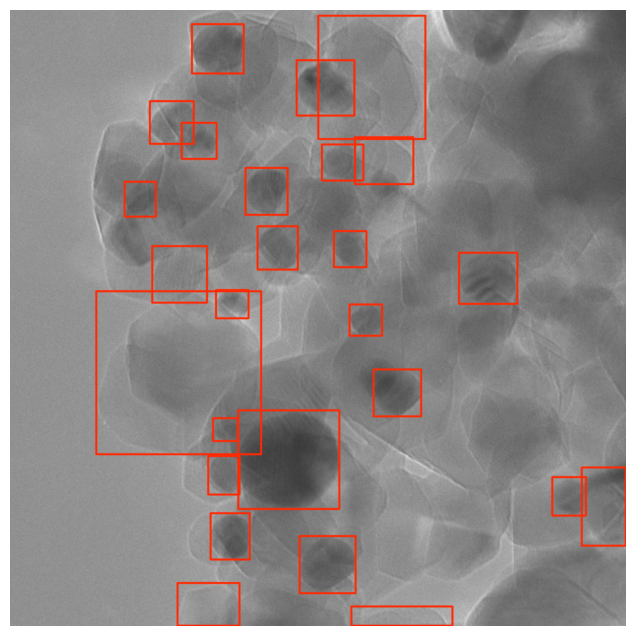

In [92]:
path_to_image = r''
boxes = object_detection(img_x, img, path_to_image, img_size = 1024, pred_score = 0.6, overlap_thr = 0.2, save = False) 

In [93]:
masks = segmentation(img_x, boxes)

In [96]:
Diameter = []
Area = []
newBoxes = []
for i in range(len(boxes)):
    mask = masks[i,:,:]
    mask = clear_border(mask)
    properties = ['area']
    props = regionprops_table(mask, properties=properties)
    y = props['area']
    A = y*pixel_size*pixel_size
    D = (np.sqrt(A/3.14))*2
    if D < 24 and D > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS 
      newBoxes.append(boxes[i])
      Area.append(A)
      Diameter.append(D)

newMasks = []
newMasks = segmentation(img_x, newBoxes)


C:\Users\ellak\AppData\Local\Temp\ipykernel_1176\2419811835.py:12: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if D < 24 and D > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS


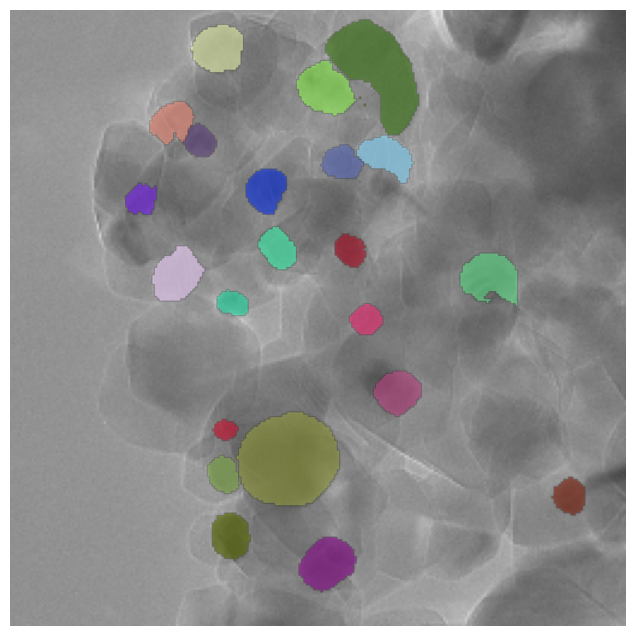

In [97]:
path_to_imageseg = r''
visualize_mask(newMasks, img, path_to_imageseg, img_size = (256, 256), save = False)

Mean Diameter : 9.55 nm
Mean Area : 82.55 nm²


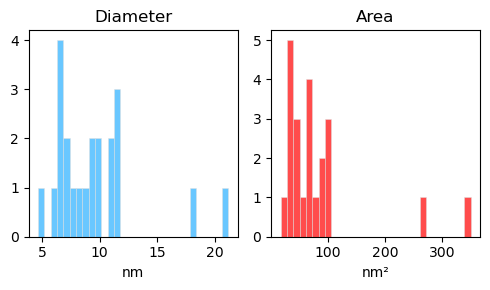

In [98]:
path_to_csv_file = r''
diameter, area = particle_analysis(newMasks, newBoxes, pixel_size, path_to_csv_file, save = False)

## Bulk code - don't worry about running this!

This section of code shows how I processed all the data - you don't need to worry about this.


0: 1024x1024 62 Particles, 69.7ms
Speed: 7.0ms preprocess, 69.7ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


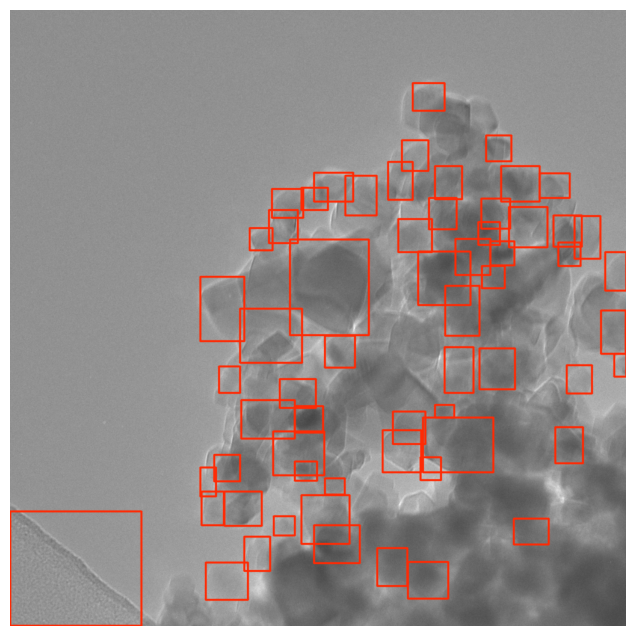


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 2672.1ms
Speed: 8.5ms preprocess, 2672.1ms inference, 206.2ms postprocess per image at shape (1, 3, 1024, 1024)


C:\Users\ellak\AppData\Local\Temp\ipykernel_31052\47490104.py:34: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if D < 40 and D > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS



0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 2472.9ms
Speed: 10.0ms preprocess, 2472.9ms inference, 192.6ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 20.14 nm
Mean Area : 346.57 nm²


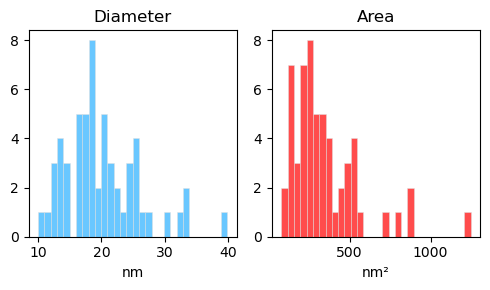


0: 1024x1024 36 Particles, 69.9ms
Speed: 6.5ms preprocess, 69.9ms inference, 1.5ms postprocess per image at shape (1, 3, 1024, 1024)


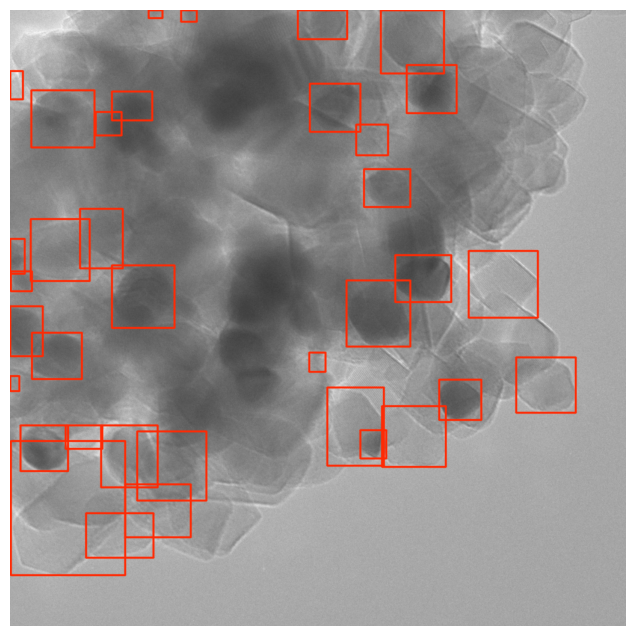


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1689.2ms
Speed: 9.0ms preprocess, 1689.2ms inference, 110.8ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1413.6ms
Speed: 9.0ms preprocess, 1413.6ms inference, 65.6ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 11.63 nm
Mean Area : 119.23 nm²


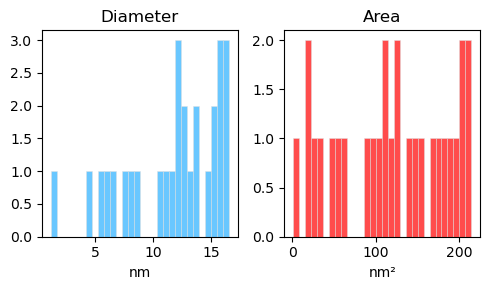


0: 1024x1024 16 Particles, 70.1ms
Speed: 5.4ms preprocess, 70.1ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


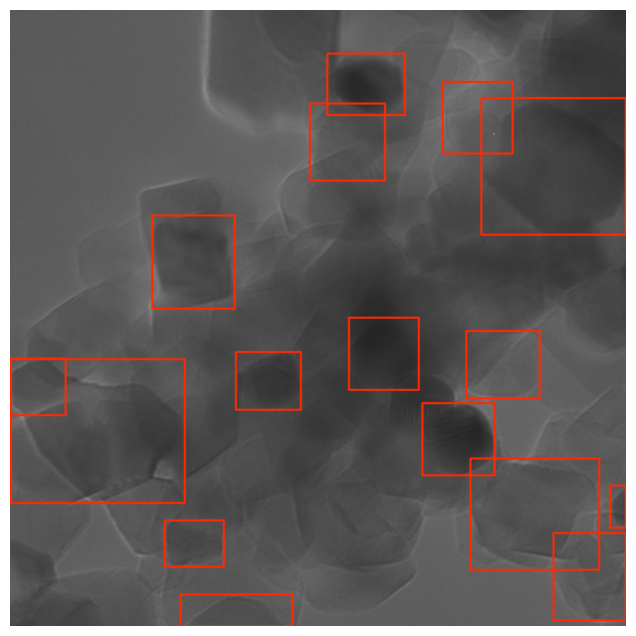


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1027.7ms
Speed: 8.3ms preprocess, 1027.7ms inference, 39.4ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 874.7ms
Speed: 10.0ms preprocess, 874.7ms inference, 25.0ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 14.72 nm
Mean Area : 178.76 nm²


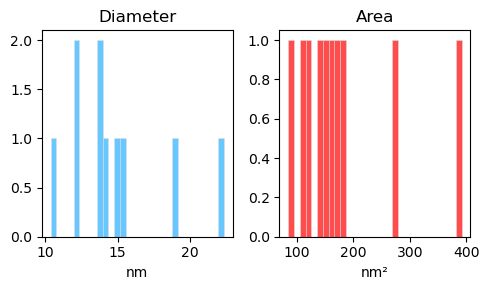


0: 1024x1024 103 Particles, 70.2ms
Speed: 5.5ms preprocess, 70.2ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


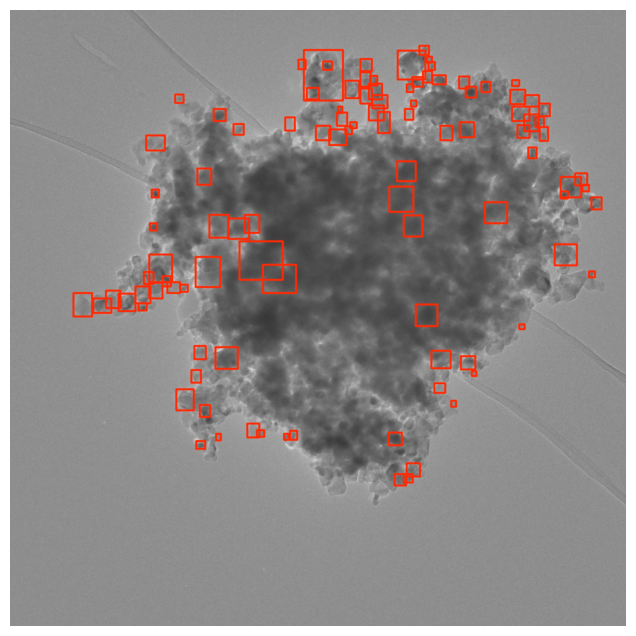


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 4280.4ms
Speed: 8.5ms preprocess, 4280.4ms inference, 318.0ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1

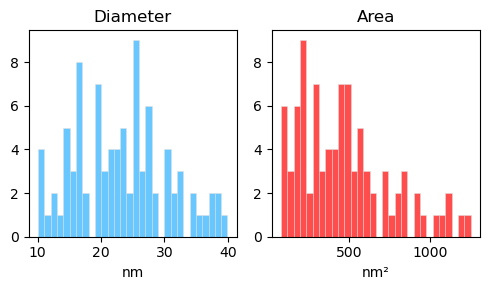


0: 1024x1024 159 Particles, 70.7ms
Speed: 5.5ms preprocess, 70.7ms inference, 3.5ms postprocess per image at shape (1, 3, 1024, 1024)


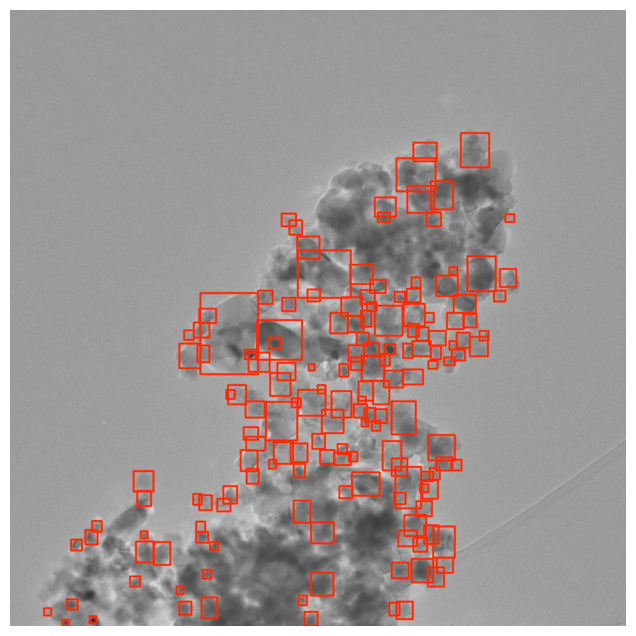


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 1 125, 1 126, 1 127, 1 128, 1 129, 1 130, 1 131, 1 132, 1 133, 1 134, 1 135, 1 136, 1 137, 1 138, 1 139, 1 140, 1 141, 1 142, 1 143, 1 144, 1 145, 1 146, 1 147, 1 148, 1 149, 1 150, 1 151, 1 152, 1 153, 1 154, 1 155, 1 15

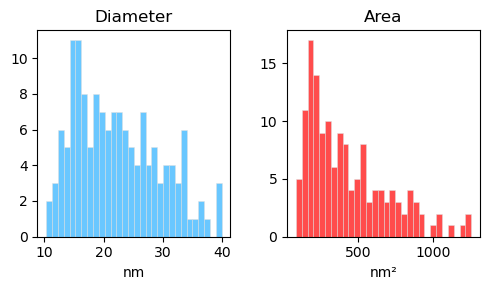


0: 1024x1024 214 Particles, 70.2ms
Speed: 6.0ms preprocess, 70.2ms inference, 3.5ms postprocess per image at shape (1, 3, 1024, 1024)


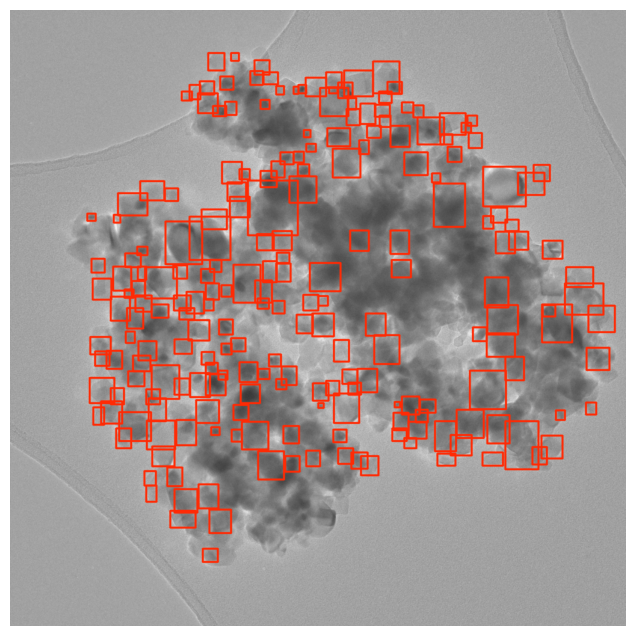


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 1 125, 1 126, 1 127, 1 128, 1 129, 1 130, 1 131, 1 132, 1 133, 1 134, 1 135, 1 136, 1 137, 1 138, 1 139, 1 140, 1 141, 1 142, 1 143, 1 144, 1 145, 1 146, 1 147, 1 148, 1 149, 1 150, 1 151, 1 152, 1 153, 1 154, 1 155, 1 15

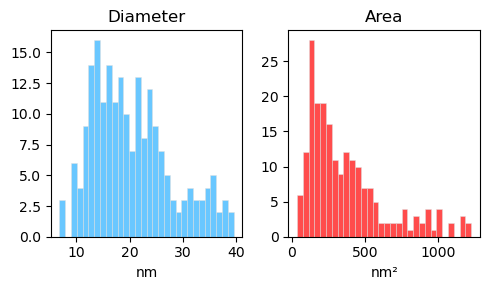


0: 1024x1024 179 Particles, 70.0ms
Speed: 6.0ms preprocess, 70.0ms inference, 4.0ms postprocess per image at shape (1, 3, 1024, 1024)


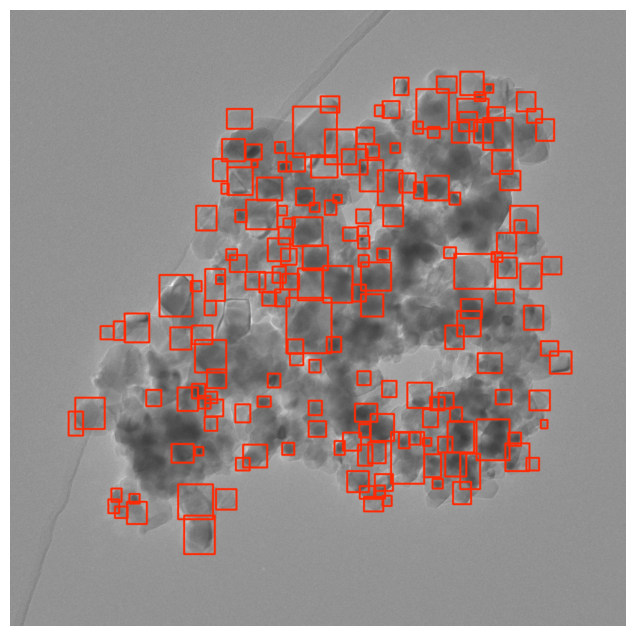


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 1 125, 1 126, 1 127, 1 128, 1 129, 1 130, 1 131, 1 132, 1 133, 1 134, 1 135, 1 136, 1 137, 1 138, 1 139, 1 140, 1 141, 1 142, 1 143, 1 144, 1 145, 1 146, 1 147, 1 148, 1 149, 1 150, 1 151, 1 152, 1 153, 1 154, 1 155, 1 15

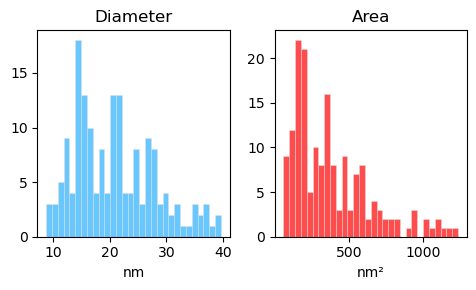


0: 1024x1024 150 Particles, 70.0ms
Speed: 5.5ms preprocess, 70.0ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


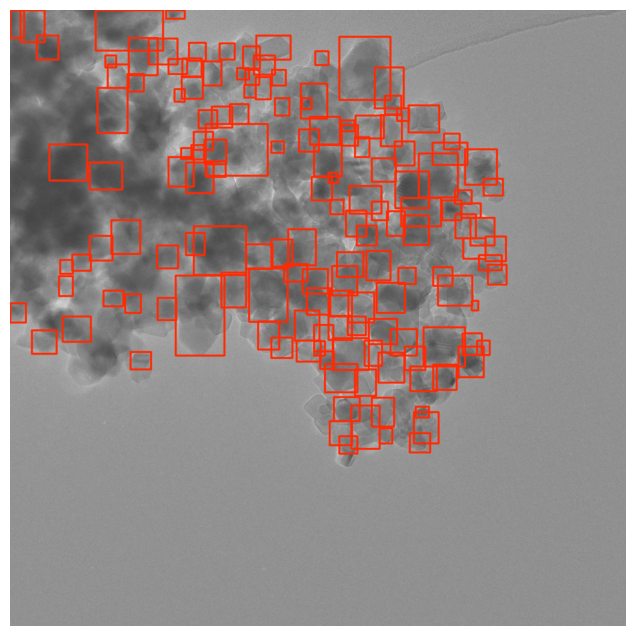


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 1 125, 1 126, 1 127, 1 128, 1 129, 1 130, 1 131, 1 132, 1 133, 1 134, 1 135, 1 136, 1 137, 1 138, 1 139, 1 140, 1 141, 1 142, 1 143, 1 144, 1 145, 1 146, 1 147, 1 148, 1 149, 6718.5ms
Speed: 9.0ms preprocess, 6718.5ms inf

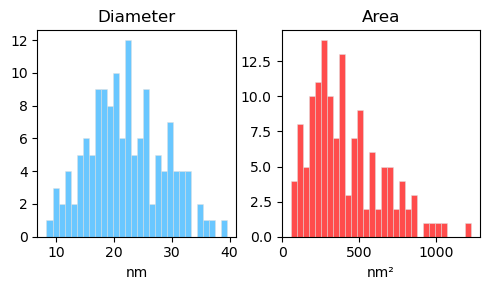


0: 1024x1024 10 Particles, 71.2ms
Speed: 6.3ms preprocess, 71.2ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


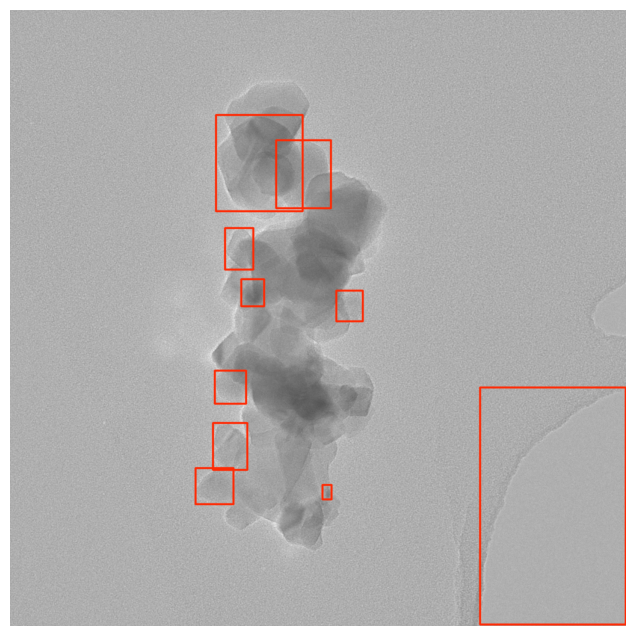


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 838.0ms
Speed: 8.0ms preprocess, 838.0ms inference, 26.1ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 774.9ms
Speed: 8.0ms preprocess, 774.9ms inference, 22.0ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 18.88 nm
Mean Area : 317.0 nm²


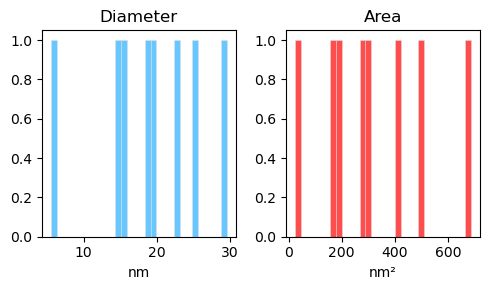


0: 1024x1024 125 Particles, 71.0ms
Speed: 6.0ms preprocess, 71.0ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


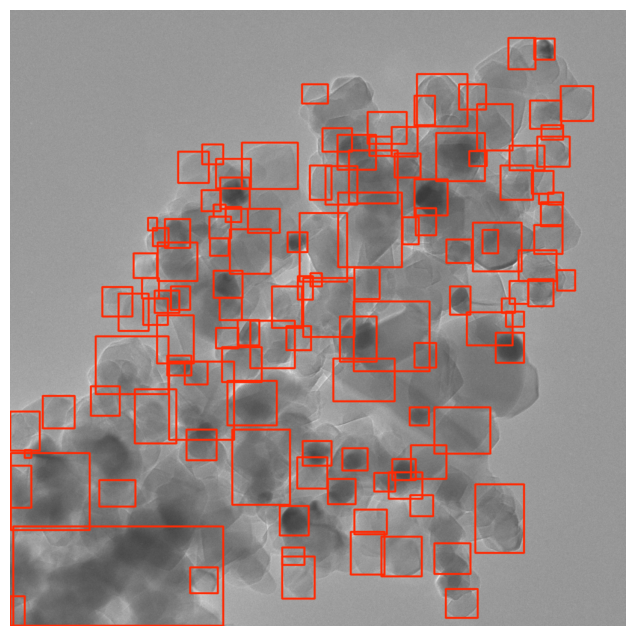


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 5069.1ms
Speed: 8.0ms preprocess, 5069.1ms inference, 431.5ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 1

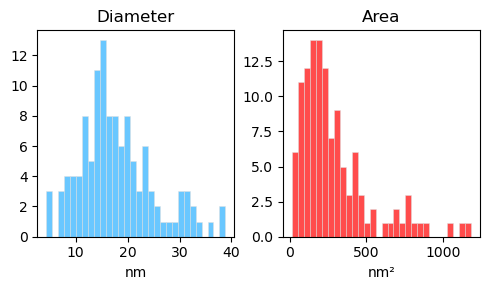


0: 1024x1024 62 Particles, 71.0ms
Speed: 5.6ms preprocess, 71.0ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


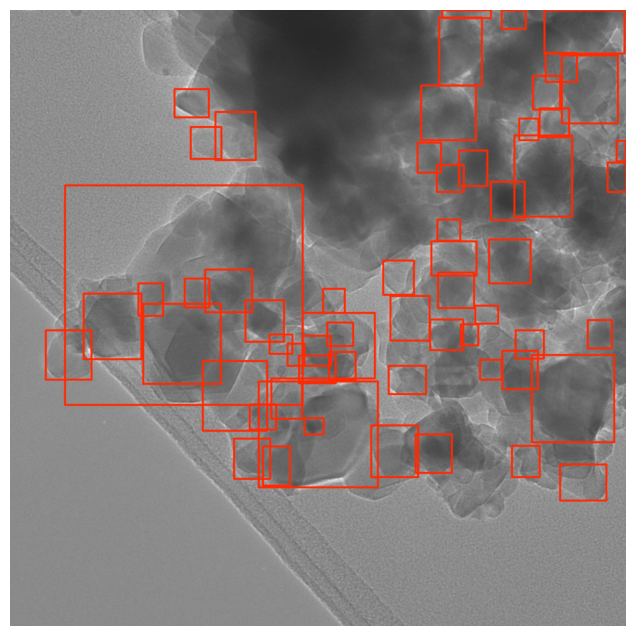


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 2597.5ms
Speed: 8.5ms preprocess, 2597.5ms inference, 206.7ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 2234.6ms
Speed: 8.0ms preprocess, 2234.6ms inference, 167.1ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 20.04 nm
Mean Area : 353.54 nm²


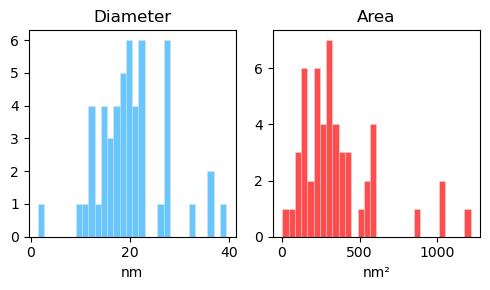


0: 1024x1024 146 Particles, 71.2ms
Speed: 6.5ms preprocess, 71.2ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


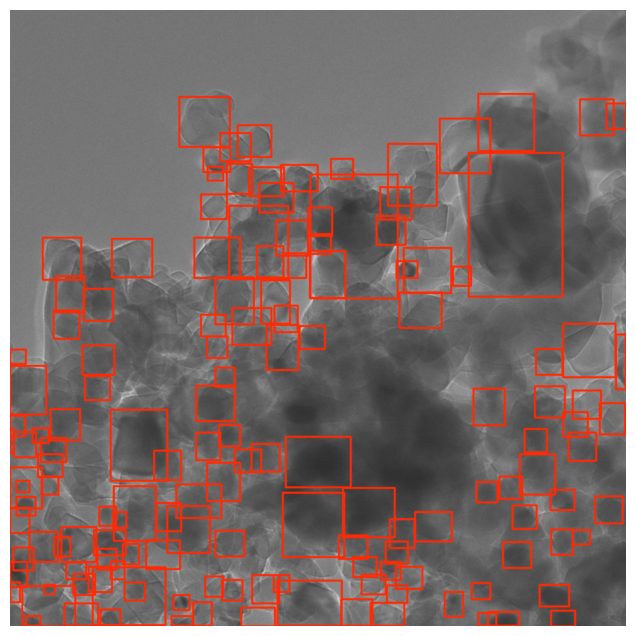


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 1 98, 1 99, 1 100, 1 101, 1 102, 1 103, 1 104, 1 105, 1 106, 1 107, 1 108, 1 109, 1 110, 1 111, 1 112, 1 113, 1 114, 1 115, 1 116, 1 117, 1 118, 1 119, 1 120, 1 121, 1 122, 1 123, 1 124, 1 125, 1 126, 1 127, 1 128, 1 129, 1 130, 1 131, 1 132, 1 133, 1 134, 1 135, 1 136, 1 137, 1 138, 1 139, 1 140, 1 141, 1 142, 1 143, 1 144, 1 145, 6395.9ms
Speed: 8.5ms preprocess, 6395.9ms inference, 343.5ms postprocess 

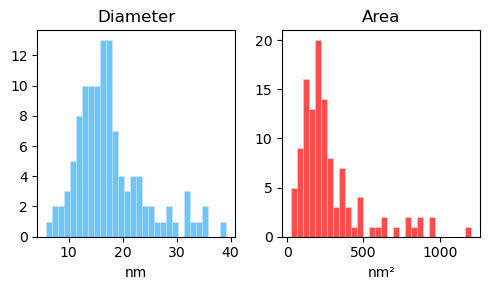


0: 1024x1024 62 Particles, 70.4ms
Speed: 6.0ms preprocess, 70.4ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


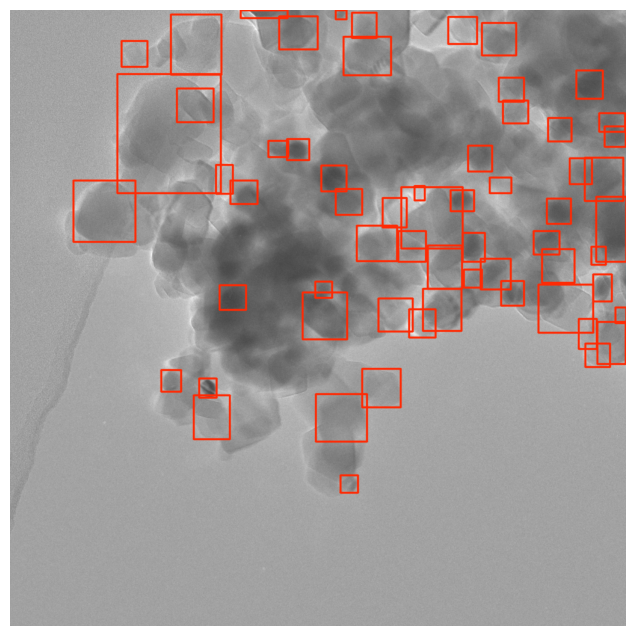


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 2571.1ms
Speed: 8.0ms preprocess, 2571.1ms inference, 215.9ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 2338.1ms
Speed: 8.5ms preprocess, 2338.1ms inference, 177.4ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 17.56 nm
Mean Area : 269.83 nm²


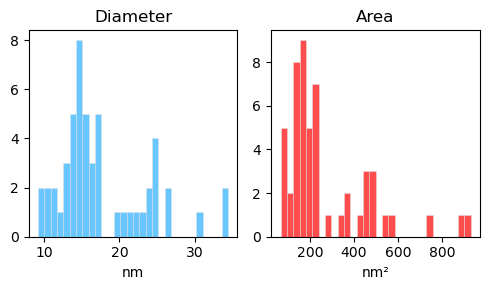


0: 1024x1024 98 Particles, 71.1ms
Speed: 5.5ms preprocess, 71.1ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


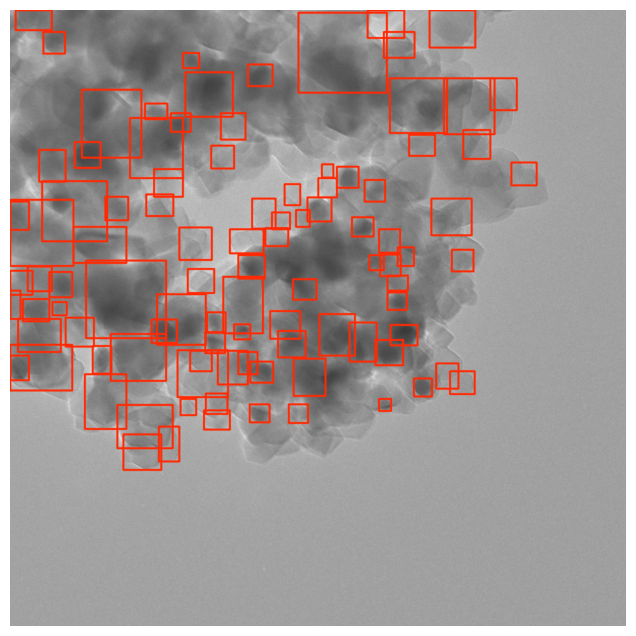


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 1 61, 1 62, 1 63, 1 64, 1 65, 1 66, 1 67, 1 68, 1 69, 1 70, 1 71, 1 72, 1 73, 1 74, 1 75, 1 76, 1 77, 1 78, 1 79, 1 80, 1 81, 1 82, 1 83, 1 84, 1 85, 1 86, 1 87, 1 88, 1 89, 1 90, 1 91, 1 92, 1 93, 1 94, 1 95, 1 96, 1 97, 4087.5ms
Speed: 9.1ms preprocess, 4087.5ms inference, 290.7ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48

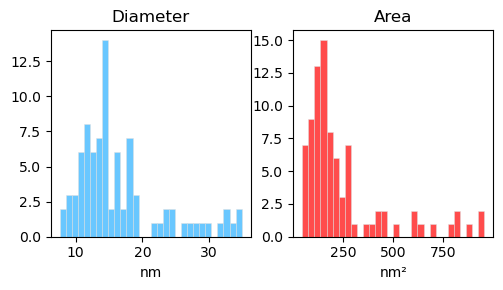


0: 1024x1024 61 Particles, 70.5ms
Speed: 5.5ms preprocess, 70.5ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


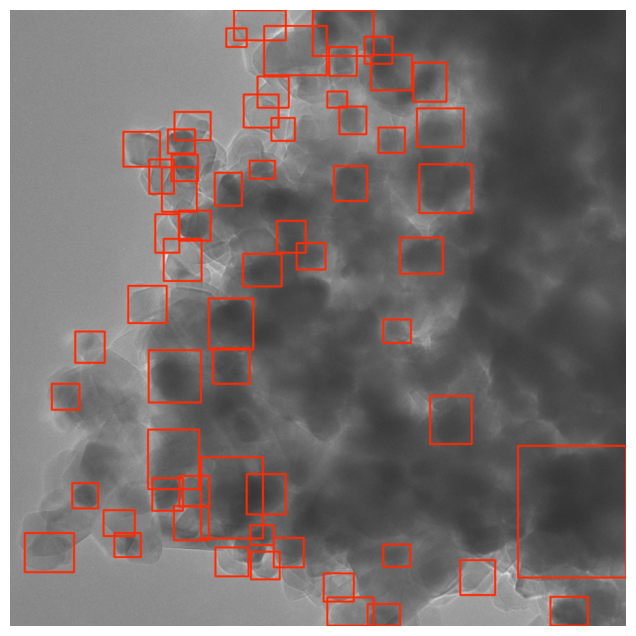


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 1 56, 1 57, 1 58, 1 59, 1 60, 2558.0ms
Speed: 8.0ms preprocess, 2558.0ms inference, 209.1ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 1 51, 1 52, 1 53, 1 54, 1 55, 2388.3ms
Speed: 8.0ms preprocess, 2388.3ms inference, 190.5ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 16.94 nm
Mean Area : 247.22 nm²


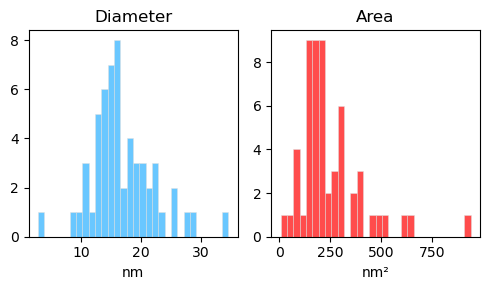


0: 1024x1024 51 Particles, 70.3ms
Speed: 5.5ms preprocess, 70.3ms inference, 3.5ms postprocess per image at shape (1, 3, 1024, 1024)


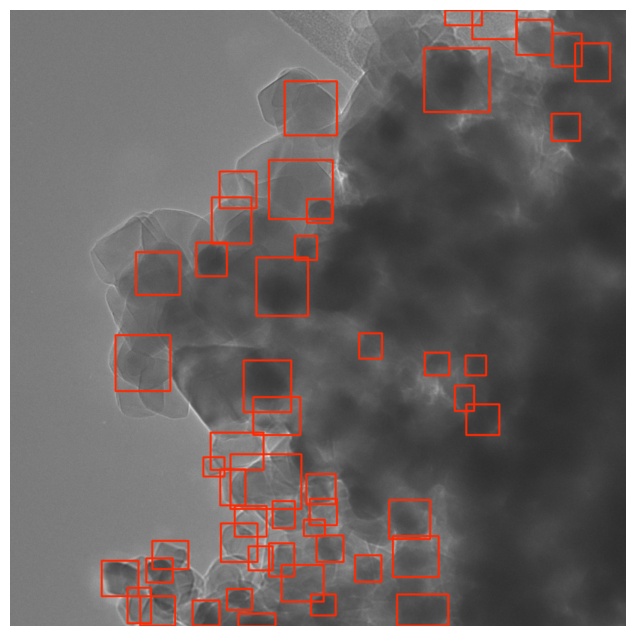


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 1 49, 1 50, 2161.6ms
Speed: 8.5ms preprocess, 2161.6ms inference, 174.3ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1973.8ms
Speed: 8.0ms preprocess, 1973.8ms inference, 175.4ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 17.65 nm
Mean Area : 273.55 nm²


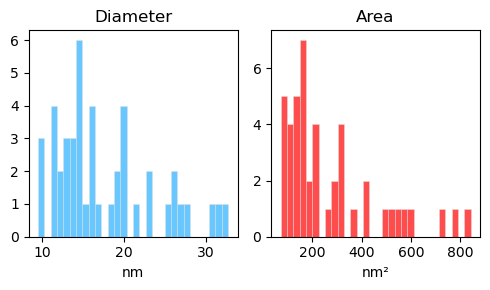


0: 1024x1024 49 Particles, 70.4ms
Speed: 6.5ms preprocess, 70.4ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


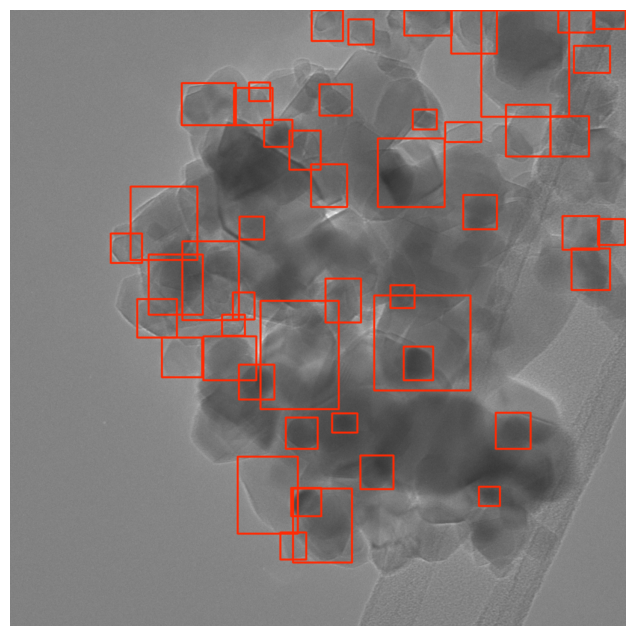


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 2099.0ms
Speed: 8.5ms preprocess, 2099.0ms inference, 162.2ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1937.5ms
Speed: 8.0ms preprocess, 1937.5ms inference, 149.0ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 18.71 nm
Mean Area : 312.31 nm²


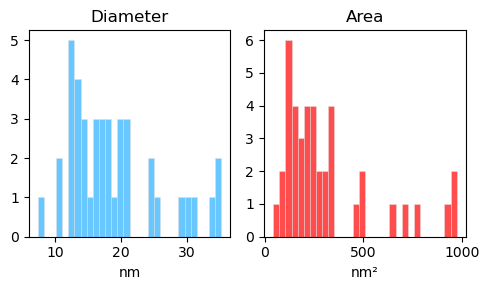


0: 1024x1024 17 Particles, 72.0ms
Speed: 5.8ms preprocess, 72.0ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)


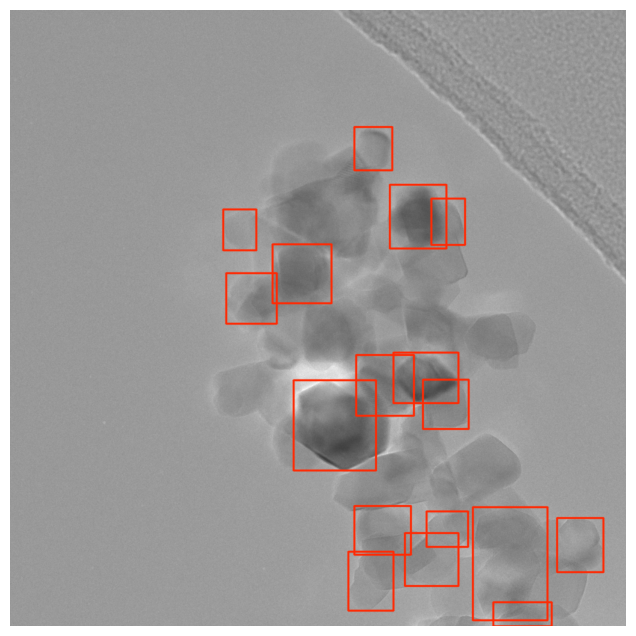


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1088.5ms
Speed: 8.5ms preprocess, 1088.5ms inference, 43.5ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1050.4ms
Speed: 8.0ms preprocess, 1050.4ms inference, 43.4ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 18.8 nm
Mean Area : 323.53 nm²


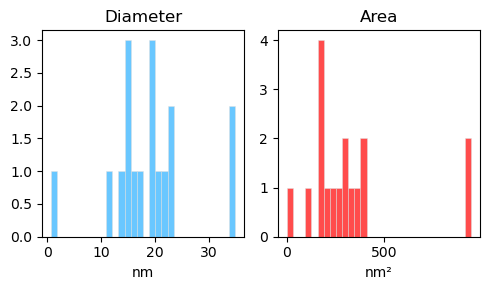


0: 1024x1024 25 Particles, 70.8ms
Speed: 5.5ms preprocess, 70.8ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 1024)


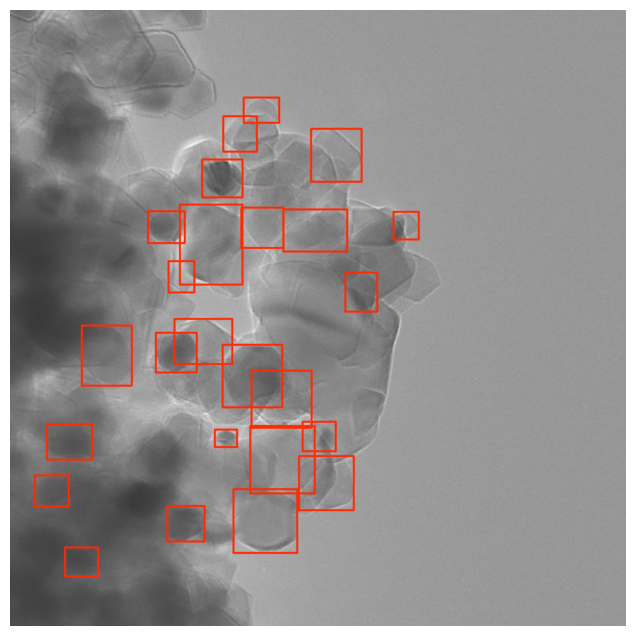


0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1268.3ms
Speed: 8.5ms preprocess, 1268.3ms inference, 59.1ms postprocess per image at shape (1, 3, 1024, 1024)

0: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1271.6ms
Speed: 8.3ms preprocess, 1271.6ms inference, 60.0ms postprocess per image at shape (1, 3, 1024, 1024)
Mean Diameter : 16.01 nm
Mean Area : 224.06 nm²


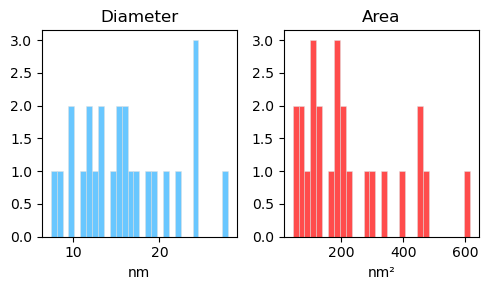

In [22]:
# Batch Processing TEM
import gc
import glob
path_to_csv_file = r''
path_to_image = r''
path_to_dm3_files = r'C:\path\Sample_3rdYRTEM\Sample5_3rdYear\*.dm3'

diameter_final = []
area_final = []
newBoxes = []
for v in glob.glob(path_to_dm3_files):
    newBoxes = []
    data = hs.load(v) #load each data file
    data_squeezed = np.squeeze(data.data[:]) #take the "data" out of the whole file - it includes metadata and other information about it, but we just want the image.
    data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8') #makes sure image is the correct data type
    img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) #makes sure the image is in correct format
    img_x = img #sets comparative image
    if data.axes_manager[0].units == 'µm':
        pixel_size = data.axes_manager.signal_axes[0].scale * 1000
    else:
        pixel_size = data.axes_manager.signal_axes[0].scale #takes the pixel size from metadata, in nm.
    with torch.no_grad(): # to make sure the memory is not unneccessarily stored!
        boxes = object_detection(img_x, img, path_to_image, img_size = 1024, pred_score = 0.5, overlap_thr = 0.2, save = False) # draws a box around the possible nanoparticles
        masks = segmentation_fast(img_x, boxes) # segments the exact nanoparticle within this box 
        # remove falsely detected support sections by thresholding a maximum
        for i in range(len(boxes)):
            mask = masks[i,:,:]
            mask = clear_border(mask)
            properties = ['area']
            props = regionprops_table(mask, properties=properties)
            y = props['area']
            A = y*pixel_size*pixel_size
            D = (np.sqrt(A/3.14))*2
            if D < 40 and D > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS 
              newBoxes.append(boxes[i])
    del boxes
    del masks
    if len(newBoxes) > 0 :
        with torch.no_grad():
            newMasks = segmentation_fast(img_x, newBoxes)
            diameter, area = particle_analysis(newMasks, newBoxes, pixel_size, path_to_csv_file, save = False) # analyses them        
            diameter_final.append(diameter) # saves the results for this dataset
            area_final.append(area) # same as above, but for area instead of diameter
            del newMasks
    del newBoxes
    del data
    del data_squeezed
    with torch.no_grad():
        torch.cuda.empty_cache()
        gc.collect()
diameter_total = np.concatenate((diameter_final))
area_total = np.concatenate((area_final))

In [23]:
# convert array into dataframe to save 
DF = pd.DataFrame(diameter_total) 
# save the dataframe as a csv file 
DF.to_csv(r"C:\path\Sample_3rdYRTEM\diameter_totalSample5.csv")


In [69]:
#if out of memory
torch.cuda.empty_cache()

In [ ]:
len(diameter_total)

In [ ]:
mean = np.mean(diameter_total)
std = np.std(diameter_total)

In [ ]:
np.round(mean, decimals = 3)

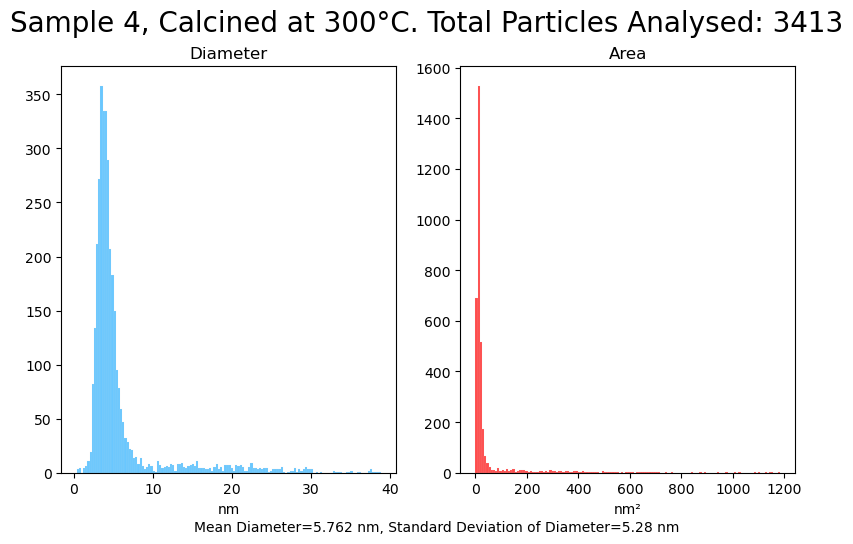

In [162]:
fig, axs = plt.subplots(1, 2, sharey = False, tight_layout = False, figsize=(8, 5))
axs[0].hist(diameter_total, bins =140, facecolor='#2ab0ff', edgecolor='#e0e0e0', linewidth=0.1, alpha=0.7)
axs[0].set_title("Diameter")
axs[0].set_xlabel('nm')
axs[1].hist(area_total, bins = 140, facecolor='red', edgecolor='#e0e0e0', linewidth=0.1, alpha=0.7)
axs[1].set_title("Area")
axs[1].set_xlabel('nm\u00b2')
fig.text(0.0, 1.0,f"Sample 5, Calcined at 600\N{DEGREE SIGN}C. Total Particles Analysed: {len(diameter_total)}", fontsize=20) #Calcined at 600\N{DEGREE SIGN}C
fig.text(.23, 0., f"Mean Diameter={np.round(mean, decimals = 3)} nm, Standard Deviation of Diameter={np.round(std, decimals = 3)} nm")
#plt.savefig(r'C:\Downloads\Sample_3rdYRTEM\Sample2_3rdYear\DiameterAreaPlot_Sample2.png')
plt.show()